# L3: Text clustering and topic modelling

Text clustering groups documents in such a way that documents within a group are more &lsquo;similar&rsquo; to other documents in the cluster than to documents not in the cluster. The exact definition of what &lsquo;similar&rsquo; means in this context varies across applications and clustering algorithms.

In this lab you will experiment with both hard and soft clustering techniques. More specifically, in the first part you will be using the $k$-means algorithm, and in the second part you will be using a topic model based on the Latent Dirichlet Allocation (LDA).

**A quick reminder about our [Rules for hand-in assignments](https://www.ida.liu.se/~TDDE16/exam.en.shtml#handins) and the [Policy on cheating and plagiarism](https://www.ida.liu.se/~TDDE16/exam.en.shtml#cheating)**

## Hard clustering data set

The raw data for the hard clustering part of this lab is a collection of product reviews. We have preprocessed the data by tokenization and lowercasing.

In [2]:
import pandas as pd
import bz2

with bz2.open('reviews.json.bz2') as source:
    df = pd.read_json(source)

When you inspect the data frame, you can see that there are three labelled columns: `category` (the product category), `sentiment` (whether the product review was classified as &lsquo;positive&rsquo; or &lsquo;negative&rsquo; towards the product), and `text` (the space-separated text of the review).

In [3]:
df.head()

,category,sentiment,text
0,music,neg,i bought this album because i loved the title ...
1,music,neg,i was misled and thought i was buying the enti...
2,books,neg,"i have introduced many of my ell , high school..."
3,books,pos,anything you purchase in the left behind serie...
4,dvd,pos,"i loved these movies , and i cant wiat for the..."


## Problem 1: K-means clustering

Your first task is to cluster the product review data using a tf–idf vectorizer and a $k$-means clusterer.

Start by doing the vectorization. In connection with vectorization, you should also filter out standard English stop words. While you could use [spaCy](https://spacy.io/) for this task, here it suffices to use the word list implemented in [TfidfVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html).

In [5]:
# TODO: Enter code here to vectorize the data and store it in a variable `reviews`

from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(stop_words='english')
reviews = vectorizer.fit_transform(df['text'])

Test your vectorization by running the following code cell:

In [6]:
reviews.shape

(11914, 46619)

If you used the English stop word list from scikit-learn, then the resulting vocabulary should have 46,619 entries.

Next, cluster the vectorized data. Before doing so, you should read the documentation of the [KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html) class, which is scikit-learn&rsquo;s implementation of the $k$-means algorithm. As you can see, this class has several parameters that you can tweak. For now, the only parameter that you will have to set is the number of clusters. Start with $k=3$.

**Tip:** Training $k$-means models will take some time. To speed things up, you can use the `n_init` parameter to control the number of times that the clustering is re-computed with different initial values. The default value for this parameter is 10; here and in the rest of this lab, you may want to set this to a lower value.

In [8]:
# TODO: Enter code here to cluster the vectorized data


from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, n_init=3, random_state=42)
cluster_labels = kmeans.fit_predict(reviews)

To sanity-check your clustering, create a bar plot with the number of documents per cluster.

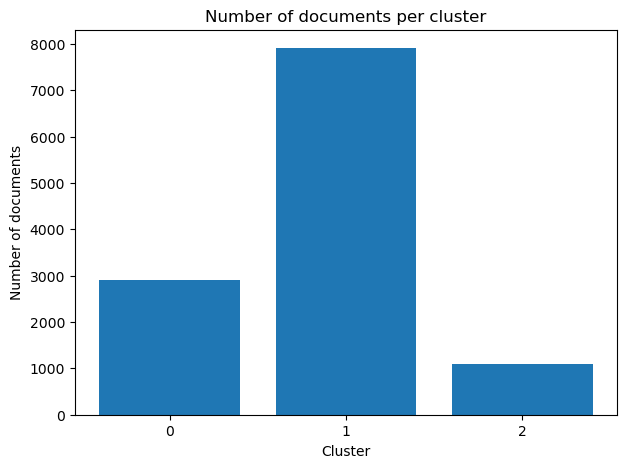

In [9]:
# TODO: Enter code here to produce a bar plot of the cluster size


import matplotlib.pyplot as plt
import numpy as np

cluster_sizes = np.bincount(cluster_labels)

plt.figure(figsize=(7, 5))
plt.bar(range(len(cluster_sizes)), cluster_sizes)
plt.xlabel('Cluster')
plt.ylabel('Number of documents')
plt.title('Number of documents per cluster')
plt.xticks(range(len(cluster_sizes)))
plt.show()

Note that sizes may vary considerable between clusters and among different random seeds.

## Problem 2: Summarize clusters

Once you have a clustering, you can try to see whether it is meaningful. One useful technique in that context is to generate a **summary** for each cluster by extracting the $n$ highest-weighted terms from the centroid of each cluster. Your next task is to implement this approach.

**Hint:** You will need to construct an &lsquo;inverted vocabulary&rsquo; that allows you to map from the index of a term back to the original term.

In [10]:
# TODO: Enter code here to compute the cluster summaries and print them


feature_names = vectorizer.get_feature_names_out()

for cluster_id in range(kmeans.n_clusters):
    top_indices = kmeans.cluster_centers_[cluster_id].argsort()[-10:][::-1]
    top_terms = [feature_names[i] for i in top_indices]
    
    print(f"Cluster {cluster_id}:")
    print(", ".join(top_terms))
    print()

Cluster 0:
book, movie, quot, film, read, story, like, just, good, great

Cluster 1:
product, like, great, cd, just, use, album, good, time, does

Cluster 2:
camera, lens, pictures, canon, digital, use, flash, battery, quality, great



Once you have computed the cluster summaries, take a minute to reflect on their quality. Is it clear what the reviews in a given cluster are about? Do the cluster summaries contain any unexpected terms?

***The clusters are partly meaningful. Cluster 2 is clearly related to cameras and photography because it contains words such as “camera”, “lens”, “pictures”, “canon”, “flash”, and “battery”. Cluster 0 is mainly related to books and movies, with words such as “book”, “movie”, “film”, “read”, and “story”. Cluster 1 is more general and contains words related to products, CDs, albums, and reviews.***

***Some terms such as “like”, “good”, “great”, and “just” are quite general and do not describe a specific topic. Therefore, the cluster summaries are useful, but they are not perfect.***

## Problem 3: Compare clusterings using the Rand index

In some scenarios, you may have gold-standard class labels available for at least a subset of your documents. In these cases you can compute the **Rand index** of a clustering, and use this measure to compare the quality of different clusterings.

To compute the Rand index, we view a clustering as a binary classifier on (unordered) pairs of documents. The classifier predicts &lsquo;positive&rsquo; if and only if the two documents belong to the same cluster. The (non-normalized) Rand index of the clustering is the accuracy of this classifier relative to a reference in which a document pair belongs to the &lsquo;positive&rsquo; class if and only if the two documents in the pair have the same gold-standard class label. You are supposed to implement the procedure yourselves, not import an external function.

Compare clusterings with $k \in \{1,3,5,7\}$ clusters. As your evaluation data, use the first 500 documents from the original data set along with their gold-standard categories (from the `category` column).

In [11]:
# TODO: Enter code here to (manually) compute the Rand indices for the two clusterings


from sklearn.cluster import KMeans

# Use the first 500 documents
X_eval = reviews[:500]
gold_labels = df['category'].iloc[:500].to_numpy()

def manual_rand_index(predicted, gold):
    correct = 0
    total = 0
    
    n = len(gold)
    
    for i in range(n):
        for j in range(i + 1, n):
            predicted_same = predicted[i] == predicted[j]
            gold_same = gold[i] == gold[j]
            
            if predicted_same == gold_same:
                correct += 1
            
            total += 1
    
    return correct / total


rand_results = {}

for k in [1, 3, 5, 7]:
    kmeans_k = KMeans(
        n_clusters=k,
        n_init=3,
        random_state=42
    )
    
    predicted_labels = kmeans_k.fit_predict(X_eval)
    
    rand = manual_rand_index(predicted_labels, gold_labels)
    rand_results[k] = rand
    
    print(f"k = {k}: Rand index = {rand:.4f}")

k = 1: Rand index = 0.1663
k = 3: Rand index = 0.6422
k = 5: Rand index = 0.7431
k = 7: Rand index = 0.7643


*TODO: Insert a summary of your results here*

***The Rand index increases as the number of clusters increases. The lowest value is obtained for k = 1 (0.1663), while the highest value is obtained for k = 7 (0.7643). This means that, among the tested values, k = 7 gives the best agreement with the gold categories. Increasing the number of clusters improves the clustering quality for this dataset.***

## Topic modelling data set

The data set for the topic modelling part of this lab is the collection of all [State of the Union](https://en.wikipedia.org/wiki/State_of_the_Union) addresses from the years 1975–2000. These speeches come as a single text file with one sentence per line. The following code cell prints the first 5 lines from the data file:

In [12]:
with open('sotu_1975_2000.txt') as source:
    for i, line in enumerate(source):
        print(line.rstrip())
        if i >= 5:
            break

mr speaker mr vice president members of the 94th congress and distinguished guests
twenty six years ago a freshman congressman a young fellow with lots of idealism who was out to change the world stood before sam rayburn in the well of the house and solemnly swore to the same oath that all of you took yesterday an unforgettable experience and i congratulate you all
two days later that same freshman stood at the back of this great chamber over there someplace as president truman all charged up by his single handed election victory reported as the constitution requires on the state of the union
when the bipartisan applause stopped president truman said i am happy to report to this 81st congress that the state of the union is good our nation is better able than ever before to meet the needs of the american people and to give them their fair chance in the pursuit of happiness it is foremost among the nations of the world in the search for peace
today that freshman member from michigan stan

Take a few minutes to think about what topics you would expect in this data set.

## Problem 4: Train a topic model

Your first task on the topic modelling data is to train an LDA model. For this task you will be using [spaCy](https://spacy.io/) and the [gensim](https://radimrehurek.com/gensim/) topic modelling library.

Start by preprocessing the data using spaCy. Given that the data set for this problem is rather small, you do not have to exclude any components from the standard pipeline. Filter out stop words, non-alphabetic tokens, and tokens less than 3 characters in length. Store the documents as a nested list where the first level of nesting corresponds to the sentences and the second level corresponds to the tokens in each sentence.

In [11]:
!python -m spacy download en_core_web_sm

     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
      --------------------------------------- 0.3/12.8 MB ? eta -:--:--
     -- ------------------------------------- 0.8/12.8 MB 1.9 MB/s eta 0:00:07
     ---- ----------------------------------- 1.3/12.8 MB 2.0 MB/s eta 0:00:06
     ---- ----------------------------------- 1.6/12.8 MB 1.9 MB/s eta 0:00:06
     ------ --------------------------------- 2.1/12.8 MB 1.9 MB/s eta 0:00:06
     ------- -------------------------------- 2.4/12.8 MB 1.8 MB/s eta 0:00:06
     -------- ------------------------------- 2.6/12.8 MB 1.8 MB/s eta 0:00:06
     --------- ------------------------------ 2.9/12.8 MB 1.7 MB/s eta 0:00:06
     --------- ------------------------------ 3.1/12.8 MB 1.7 MB/s eta 0:00:06
     ----------- ---------------------------- 3.7/12.8 MB 1.7 MB/s eta 0:00:06
 

In [14]:
# TODO: Replace the following lines with your own code for preprocessing the documents

import spacy

nlp = spacy.load("en_core_web_sm")

with open('sotu_1975_2000.txt') as source:
    texts = [line.strip() for line in source]

documents = []

for text in texts:
    doc = nlp(text)
    
    tokens = [
        token.text.lower()
        for token in doc
        if token.is_alpha
        and not token.is_stop
        and len(token.text) >= 3
    ]
    
    documents.append(tokens)

Test your preprocessing by running the following cell:

In [15]:
' '.join(documents[42])

'reduce oil imports million barrels day end year million barrels day end'

You should get the following output:

Once you have the list of documents, skim the section [Pre-process and vectorize the documents](https://radimrehurek.com/gensim/auto_examples/tutorials/run_lda.html#pre-process-and-vectorize-the-documents) of the gensim documentation to learn how to create the dictionary and the vectorized corpus representation required by gensim. (Note that you cannot use the standard scikit-learn pipeline in this case.) Then, write code to train an [LdaModel](https://radimrehurek.com/gensim/models/ldamodel.html) for $k=10$ topics, and using default values for all other parameters.

In [17]:
!pip install gensim

   ---------------------------------------- 0.0/24.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/24.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/24.4 MB ? eta -:--:--
   - -------------------------------------- 0.8/24.4 MB 3.0 MB/s eta 0:00:08
   - -------------------------------------- 1.0/24.4 MB 2.2 MB/s eta 0:00:11
   -- ------------------------------------- 1.6/24.4 MB 3.1 MB/s eta 0:00:08
   ---- ----------------------------------- 2.9/24.4 MB 3.3 MB/s eta 0:00:07
   ----- ---------------------------------- 3.4/24.4 MB 3.1 MB/s eta 0:00:07
   ------ --------------------------------- 3.7/24.4 MB 3.3 MB/s eta 0:00:07
   ------ --------------------------------- 4.2/24.4 MB 2.9 MB/s eta 0:00:07
   ------ --------------------------------- 4.2/24.4 MB 2.9 MB/s eta 0:00:07
   ------- -------------------------------- 4.7/24.4 MB 2.4 MB/s eta 0:00:09
   -------- ------------------------------- 5.2/24.4 MB 2.4 MB/s eta 0:00:08
   --------- -------

In [16]:
# TODO: Enter code here to train an LDA model and store it in a variable `model`
from gensim.corpora import Dictionary
from gensim.models import LdaModel

dictionary = Dictionary(documents)

corpus = [
    dictionary.doc2bow(document)
    for document in documents
]

model = LdaModel(
    corpus=corpus,
    id2word=dictionary,
    num_topics=10
)

Once you have a trained model, run the following cell to print the topics:

In [17]:
model.print_topics()

[(0,
  '0.011*"new" + 0.007*"people" + 0.006*"work" + 0.006*"let" + 0.006*"americans" + 0.006*"cancer" + 0.006*"nation" + 0.005*"welfare" + 0.005*"america" + 0.005*"union"'),
 (1,
  '0.019*"new" + 0.010*"work" + 0.010*"health" + 0.009*"people" + 0.008*"congress" + 0.008*"america" + 0.007*"year" + 0.007*"college" + 0.007*"care" + 0.007*"years"'),
 (2,
  '0.014*"years" + 0.011*"crime" + 0.010*"new" + 0.009*"people" + 0.009*"world" + 0.006*"year" + 0.006*"time" + 0.006*"america" + 0.006*"congress" + 0.005*"work"'),
 (3,
  '0.013*"people" + 0.013*"government" + 0.012*"work" + 0.011*"new" + 0.008*"american" + 0.007*"children" + 0.007*"congress" + 0.007*"support" + 0.007*"families" + 0.006*"let"'),
 (4,
  '0.015*"america" + 0.014*"world" + 0.010*"new" + 0.008*"years" + 0.007*"nation" + 0.006*"peace" + 0.006*"security" + 0.005*"economy" + 0.005*"people" + 0.005*"technology"'),
 (5,
  '0.009*"welfare" + 0.009*"work" + 0.008*"education" + 0.007*"schools" + 0.006*"help" + 0.006*"school" + 0.006*

Inspect the topics. Can you &lsquo;label&rsquo; each topic with a short description of what it is about? Do the topics match your expectations?

Topic labels:

Topic 0 — America and society: America, people, world, years, work, children.

Topic 1 — Family and social issues: people, families, children, work, America.

Topic 2 — Congress, crime and welfare: Congress, crime, welfare, members, people.

Topic 3 — Government budget and economy: budget, government spending, billion, Congress.

Topic 4 — Government, education and schools: government, children, school, federal programs.

Topic 5 — Economy and trade: economy, schools, trade, community, work.

Topic 6 — Health care: health, care, insurance, Americans, children.

Topic 7 — National security and government: security, Congress, America, world.

Topic 8 — Politics and American society: people, Congress, America, work, world.

Topic 9 — Immigration and discrimination: immigrants, laws, illegal immigration, discrimination, opportunity.

Answer:

The topics mostly match my expectations. The model found several meaningful themes, such as health care, government and budget, education, national security, and immigration. Some topics are less clearly separated because they contain general words such as “people”, “America”, “work”, and “new”. This is expected because these words can appear in many political speeches. Overall, the LDA model produced understandable topics.

## Problem 5: Monitor a topic model for convergence

When learning an LDA model, it is important to make sure that the training algorithm has converged to a stable posterior distribution. One way to do so is to plot, after each training epochs (or &lsquo;pass&rsquo;, in gensim parlance) the log likelihood of the training data under the posterior. Your last task in this lab is to create such a plot and, based on this, to suggest an appropriate number of epochs.

To collect information about the posterior likelihood after each pass, we need to enable the logging facilities of gensim. Once this is done, gensim will add various diagnostics to a log file `gensim.log`.

In [18]:
import logging

logging.basicConfig(filename='gensim.log', format='%(asctime)s:%(levelname)s:%(message)s', level=logging.INFO)

The following function will parse the generated logfile and return the list of log likelihoods.

In [19]:
import re

def parse_logfile():
    matcher = re.compile('(-*\d+\.\d+) per-word .* (\d+\.\d+) perplexity')
    likelihoods = []
    with open('gensim.log') as source:
        for line in source:
            match = matcher.search(line)
            if match:
                likelihoods.append(float(match.group(1)))
    return likelihoods

Your task now is to re-train your LDA model for 50&nbsp;passes, retrieve the list of log likelihoods, and create a plot from this data.

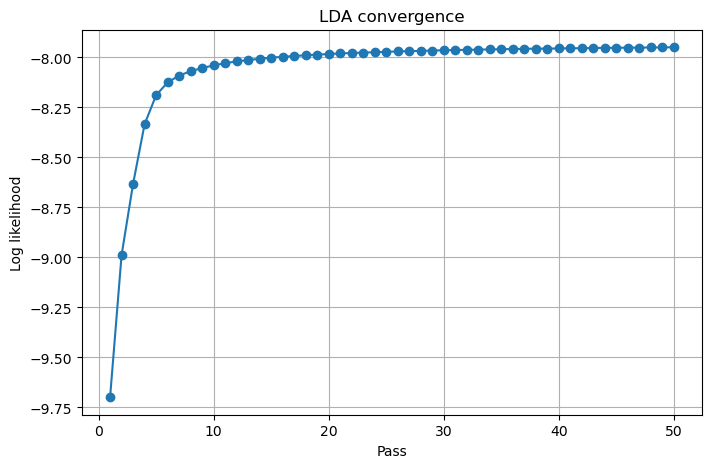

In [20]:
# TODO: Enter code here to generate the convergence plot

from gensim.models import LdaModel
import matplotlib.pyplot as plt

model_50 = LdaModel(
    corpus=corpus,
    id2word=dictionary,
    num_topics=10,
    passes=50
)

likelihoods = parse_logfile()

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(likelihoods) + 1), likelihoods, marker='o')
plt.xlabel('Pass')
plt.ylabel('Log likelihood')
plt.title('LDA convergence')
plt.grid(True)
plt.show()

How do you interpret your plot? Based on the plot, what would be a reasonable choice for the number of passes? Retrain your LDA model with that number and re-inspect the topics it finds. Do you consider the new topics to be &lsquo;better&rsquo; than the ones that you got from the 1-pass model in Problem&nbsp;4?

***The plot shows that the log likelihood improves rapidly during the first several passes. After about 15–20 passes, the curve becomes almost flat, which means that the LDA model is close to convergence. Further passes provide only small improvements. Therefore, 20 passes is a reasonable choice. I will retrain the model with 20 passes and compare its topics with the topics from the 1-pass model.***

In [21]:
model = LdaModel(
    corpus=corpus,
    id2word=dictionary,
    num_topics=10,
    passes=20
)

In [22]:
model.print_topics()

[(0,
  '0.013*"crime" + 0.013*"government" + 0.012*"budget" + 0.012*"federal" + 0.009*"help" + 0.009*"drugs" + 0.008*"billion" + 0.008*"percent" + 0.006*"leadership" + 0.006*"local"'),
 (1,
  '0.014*"nato" + 0.011*"rights" + 0.010*"allies" + 0.009*"scientists" + 0.009*"human" + 0.008*"support" + 0.007*"soviet" + 0.006*"countries" + 0.006*"arms" + 0.006*"europe"'),
 (2,
  '0.012*"schools" + 0.010*"state" + 0.010*"years" + 0.007*"union" + 0.007*"economic" + 0.006*"year" + 0.005*"states" + 0.005*"national" + 0.005*"high" + 0.005*"nation"'),
 (3,
  '0.018*"children" + 0.014*"work" + 0.014*"people" + 0.013*"care" + 0.013*"health" + 0.011*"congress" + 0.010*"year" + 0.010*"child" + 0.010*"know" + 0.009*"welfare"'),
 (4,
  '0.013*"tax" + 0.009*"year" + 0.008*"people" + 0.008*"government" + 0.008*"security" + 0.008*"nuclear" + 0.007*"years" + 0.006*"budget" + 0.006*"congress" + 0.006*"spending"'),
 (5,
  '0.019*"years" + 0.016*"american" + 0.011*"people" + 0.011*"inflation" + 0.009*"year" + 0.

## Reflection questions

The following reflection questions will help you prepare for the diagnostic test. Answer each of them in the form of a short text and put your answers in the cell below. You will get feedback on your answers from your lab assistant.

**RQ 3.1:** Based on your experiments in Problem&nbsp;2 and Problem&nbsp;3, what is the relation between the quality of a clustering and the number of clusters? What happens when the number of clusters is too low, or too high? For this particular data set, what would a &lsquo;good&rsquo; number of clusters be?

**RQ 3.2:** Explain why it is important to monitor an LDA model for convergence and not simply use, say, 1000&nbsp;passes. How is the log likelihood used in this context? Were the topics from the multi-pass model &lsquo;better&rsquo; than the topics from the 1-pass model?

**RQ 3.3:** What are the differences between $k$-means and LDA? When would you use one, when the other?

### RQ 3.1

The quality of clustering depends on the number of clusters. In our experiment, the Rand index increased as the number of clusters increased: it was 0.1663 for k = 1, 0.6422 for k = 3, 0.7431 for k = 5, and 0.7643 for k = 7. Too few clusters can combine different categories into the same group. Too many clusters can divide the data into small groups that are difficult to interpret. For this dataset, k = 7 gave the best result among the tested values. However, k = 5 could also be a reasonable choice if we want fewer and simpler clusters.

### RQ 3.2

It is important to monitor LDA convergence because training for 1000 passes can waste time if the model has already converged. Log likelihood helps us monitor how the model improves during training. When the curve becomes almost flat, additional passes provide only small improvements. In our experiment, the curve became nearly flat after about 15–20 passes, so 20 passes is a reasonable choice. A multi-pass model can learn more stable and coherent topics than a 1-pass model, although the topics should be compared to determine whether they are actually easier to interpret.

### RQ 3.3

K-means and LDA are different methods for analysing text. K-means is a clustering algorithm that divides documents into a fixed number of groups, and each document belongs to one cluster. LDA is a topic modelling method that discovers hidden topics in a collection of documents. A document can contain several topics with different proportions. I would use K-means when I want to group documents into separate clusters, and LDA when I want to discover the main themes discussed across documents.

**Congratulations on finishing L3! 👍**